a = 5.43099542 Angstrom
Indirect gap = 1.17292494 eV
CBM along Gamma-X = 0.84618679 * (2 pi/a)
Gamma direct gap = 3.27005236 eV
Gamma valence SOC splitting = 43.98430 meV
Longitudinal mass = 0.900209 m_e (paper: 0.900)
Transverse mass = 0.196541 m_e (paper: 0.197)



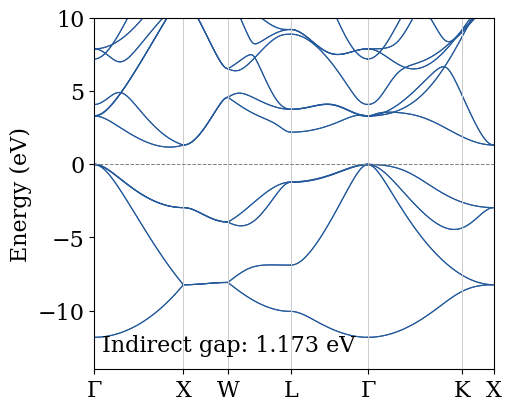

In [1]:
"""Run: python plot_silicon_bands.py --output results
Produces the full 40-band path, with a near-gap plotting window.
"""
# from pathlib import Path
# import argparse
import numpy as np
# import matplotlib
# matplotlib.use('Agg')
%matplotlib inline
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from silicon_unstrained import A, bloch_hamiltonian

plt.rcParams.update({'font.family':'serif','font.serif':['DejaVu Serif'],
                     'mathtext.fontset':'dejavuserif','font.size':16,
                     'axes.labelsize':16,'xtick.labelsize':16,'ytick.labelsize':16})


# def main(output='results'):
    # output=Path(output); output.mkdir(parents=True,exist_ok=True)
    # Cartesian reciprocal coordinates, in units 2*pi/a (FCC Brillouin zone).
# Path of Niquet et al., Fig. 1:  Gamma - X - W - L - Gamma - K - X
# (the final K - X runs on along [110] from Gamma to X' = (1,1,0), equivalent to X)
nodes=np.array([[0,0,0],        # Gamma
                [1,0,0],        # X
                [1,.5,0],       # W
                [.5,.5,.5],     # L
                [0,0,0],        # Gamma
                [.75,.75,0],    # K
                [1,1,0]])       # X' (equivalent to X)

labels=[r'$\Gamma$','X','W','L',r'$\Gamma$','K','X']
segments=[(0,1),(1,2),(2,3),(3,4),(4,5),(5,6)]

klist=[] 
distance=[] 
ticks=[0.] 
accumulated=0.

for start,end in segments:
    ks=np.linspace(nodes[start],nodes[end],121)
    ds=np.linspace(0,np.linalg.norm(nodes[end]-nodes[start])*2*np.pi/A,121)
    klist.extend(ks*2*np.pi/A); distance.extend(accumulated+ds)
    accumulated+=ds[-1] 
    ticks.append(accumulated)

klist=np.asarray(klist) 
distance=np.asarray(distance)

ev=np.array([np.linalg.eigvalsh(bloch_hamiltonian(k)) for k in klist])
gamma=np.linalg.eigvalsh(bloch_hamiltonian([0,0,0]))
vbm=gamma[7] 
ev-=vbm

f=lambda x: np.linalg.eigvalsh(bloch_hamiltonian(np.array([x,0,0])*2*np.pi/A))[8]
minimum=minimize_scalar(f,bounds=(.6,.99),method='bounded',options={'xatol':1e-12})
k0=np.array([minimum.x,0,0])*2*np.pi/A
step=1e-4
e0=np.linalg.eigvalsh(bloch_hamiltonian(k0))[8]
masses=[]
for axis in [0,1]:
    dk=np.eye(3)[axis]*step
    curvature=(np.linalg.eigvalsh(bloch_hamiltonian(k0+dk))[8]-2*e0+
                np.linalg.eigvalsh(bloch_hamiltonian(k0-dk))[8])/step**2
    masses.append(7.619964232/curvature)  # hbar^2/m_e in eV Angstrom^2

report=(f'a = {A:.8f} Angstrom\n'
        f'Indirect gap = {minimum.fun-vbm:.8f} eV\n'
        f'CBM along Gamma-X = {minimum.x:.8f} * (2 pi/a)\n'
        f'Gamma direct gap = {gamma[8]-vbm:.8f} eV\n'
        f'Gamma valence SOC splitting = {(gamma[7]-gamma[3])*1000:.5f} meV\n'
        f'Longitudinal mass = {masses[0]:.6f} m_e (paper: 0.900)\n'
        f'Transverse mass = {masses[1]:.6f} m_e (paper: 0.197)\n')
print(report) 
# ('silicon_diagnostics.txt').write_text(report)
# np.savez_compressed(output/'silicon_bands.npz',k_angstrom_inverse=klist,
                    # path_distance=distance,energy_eV=ev,vbm_raw_eV=vbm)

fig,ax=plt.subplots(figsize=(5,4),layout='constrained')
# The path is continuous (no jumps), so all segments can be drawn together.
for s in range(len(segments)):
    sl=slice(121*s,121*(s+1))
    ax.plot(distance[sl],ev[sl],color="#245a9c",lw=.8)
# ax.plot(distance,ev,color="#245a9c",lw=.8)
for tick in ticks: ax.axvline(tick,color='0.8',lw=.7)
ax.axhline(0,color='0.5',ls='--',lw=.7)
ax.set(xticks=ticks,
       xticklabels=labels,
       xlim=(0,distance[-1]),
       ylim=(-14,10),
        ylabel='Energy (eV)')
ax.text(.02,.1,f'Indirect gap: {minimum.fun-vbm:.3f} eV',transform=ax.transAxes,va='top')
fig.savefig('silicon_bands.png',dpi=180)
fig.savefig('silicon_bands.svg',dpi=180)
plt.show()
# plt.close(fig)



# parser=argparse.ArgumentParser() 
# parser.add_argument('--output',default='results')
# main(parser.parse_args().output)


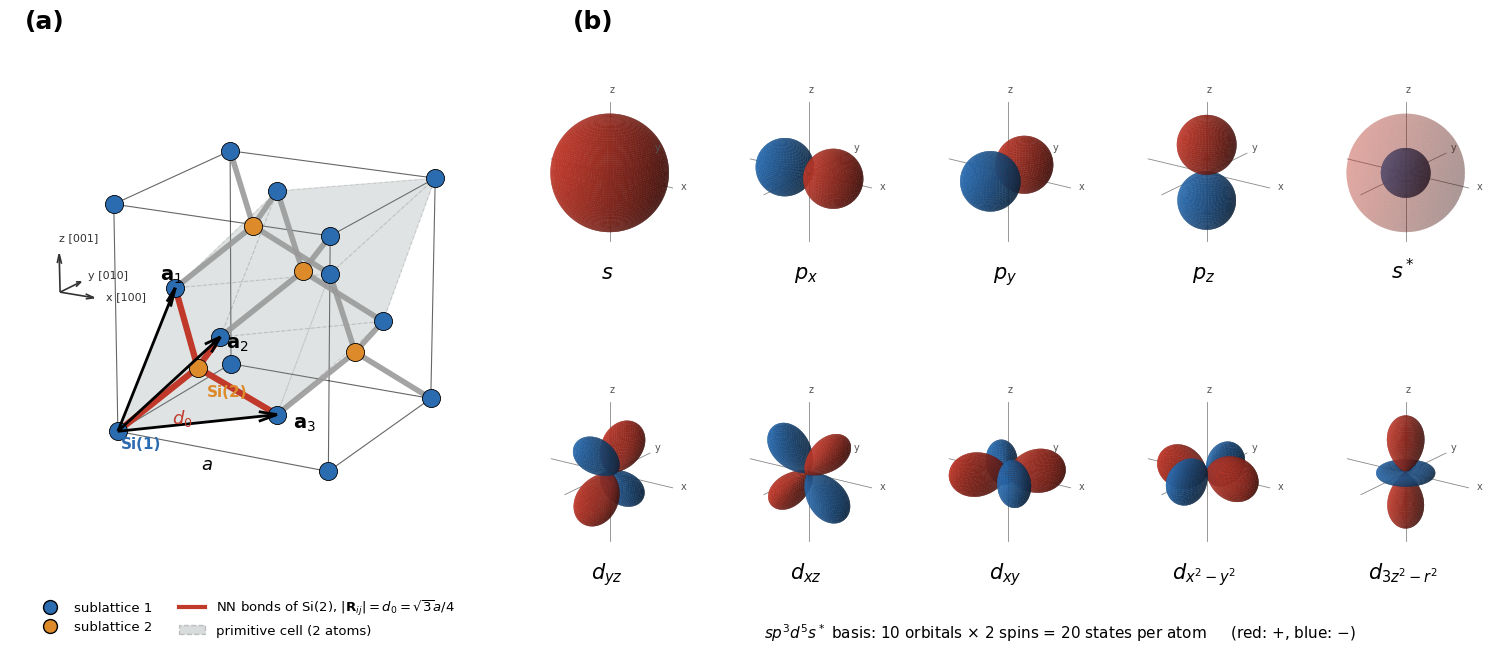

In [2]:
"""
Si diamond lattice + sp3d5s* orbital basis schematic
(notation of Niquet et al., PRB 79, 245201 (2009)).

Panel (a): conventional cubic cell, two FCC sublattices, nearest-neighbour bonds,
           primitive cell spanned by a1 = a/2(0,1,1), a2 = a/2(1,0,1), a3 = a/2(1,1,0),
           two-atom basis Si(1) at 0 and Si(2) at a/4(1,1,1), and the tetrahedron of
           bond vectors around Si(2).
Panel (b): the ten orbitals per atom, drawn as |angular part| surfaces coloured by sign.

All geometry is generated from exact fractional coordinates (units of a).
Run:  python si_unitcell_orbitals.py   -> si_unitcell_orbitals.pdf / .png
"""
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from mpl_toolkits.mplot3d.art3d import Poly3DCollection, Line3DCollection

# ----------------------------------------------------------------- style
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "mathtext.fontset": "dejavusans",
})
C_SUB1 = "#2b6cb0"   # sublattice 1 (blue)
C_SUB2 = "#dd8a2a"   # sublattice 2 (orange)
C_BOND = "#9a9a9a"
C_TET = "#c0392b"    # highlighted bonds around Si(2)
C_POS = "#c0392b"    # orbital positive lobe (red)
C_NEG = "#2b6cb0"    # orbital negative lobe (blue)
VIEW = dict(elev=18, azim=-62)

# ----------------------------------------------------------------- lattice
def fcc_in_cube():
    """FCC sites (units of a) in the closed unit cube: corners + face centres."""
    pts = []
    for p in itertools.product([0, 0.5, 1], repeat=3):
        if (2 * sum(p)) % 2 == 0:          # x+y+z integer  -> FCC site
            pts.append(p)
    return np.array(pts, float)

sub1 = fcc_in_cube()                                   # 14 atoms
sub2 = np.array([p + 0.25 for p in fcc_in_cube()
                 if np.all(p + 0.25 <= 1 + 1e-9)])     # 4 interior atoms
d0 = np.sqrt(3) / 4                                    # NN distance / a

bonds = [(p, q) for p in sub1 for q in sub2
         if abs(np.linalg.norm(p - q) - d0) < 1e-6]

a1 = 0.5 * np.array([0, 1, 1])
a2 = 0.5 * np.array([1, 0, 1])
a3 = 0.5 * np.array([1, 1, 0])
si1 = np.zeros(3)
si2 = np.array([0.25, 0.25, 0.25])


def draw_panel_a(ax):
    # cube wireframe
    edges = []
    for p in itertools.product([0, 1], repeat=3):
        for k in range(3):
            if p[k] == 0:
                q = list(p); q[k] = 1
                edges.append([p, q])
    ax.add_collection3d(Line3DCollection(edges, colors="k", lw=0.8, alpha=0.6, zorder=0))

    # primitive cell (parallelepiped)
    V = lambda i, j, k: i * a1 + j * a2 + k * a3
    faces = []
    for fixed in range(3):
        for val in (0, 1):
            quad = []
            for s, t in [(0, 0), (1, 0), (1, 1), (0, 1)]:
                ijk = [0, 0, 0]
                free = [m for m in range(3) if m != fixed]
                ijk[fixed] = val; ijk[free[0]] = s; ijk[free[1]] = t
                quad.append(V(*ijk))
            faces.append(quad)
    ax.add_collection3d(Poly3DCollection(faces, facecolor="#7f8c8d", alpha=0.13,
                                         edgecolor="#555", linestyle="--", lw=0.8, zorder=1))

    # bonds
    tet = [b for b in bonds if np.allclose(b[1], si2)]
    other = [b for b in bonds if not np.allclose(b[1], si2)]
    ax.add_collection3d(Line3DCollection(other, colors=C_BOND, lw=4, alpha=0.9, zorder=2))
    ax.add_collection3d(Line3DCollection(tet, colors=C_TET, lw=4.5, zorder=3))

    # atoms
    ax.scatter(*sub1.T, s=170, c=C_SUB1, edgecolors="k", linewidths=0.6,
               depthshade=False, zorder=5)
    ax.scatter(*sub2.T, s=170, c=C_SUB2, edgecolors="k", linewidths=0.6,
               depthshade=False, zorder=5)

    # primitive vectors
    for v, lab, off in [(a1, r"$\mathbf{a}_1$", (0.0, -0.13, 0.07)),
                        (a2, r"$\mathbf{a}_2$", (0.06, -0.06, -0.02)),
                        (a3, r"$\mathbf{a}_3$", (0.05, 0.05, -0.07))]:
        ax.quiver(0, 0, 0, *v, color="k", lw=2.0, arrow_length_ratio=0.12, zorder=6)
        ax.text(*(v + np.array(off)), lab, fontsize=14, weight="bold", zorder=10)

    # basis labels and d0
    ax.text(*(si1 + [-0.06, 0.12, -0.13]), "Si(1)", color=C_SUB1, fontsize=11,
            weight="bold", zorder=10)
    ax.text(*(si2 + [0.08, -0.06, -0.10]), "Si(2)", color=C_SUB2, fontsize=11,
            weight="bold", zorder=10)
    mid = 0.5 * (si1 + si2)
    ax.text(*(mid + [0.08, -0.02, -0.09]), r"$d_0$", color=C_TET, fontsize=13, zorder=10)

    # lattice constant along x edge
    ax.text(0.5, -0.12, -0.04, r"$a$", fontsize=13, ha="center", zorder=10)

    # Cartesian triad (offset outside the cube)
    o = np.array([-0.03, -0.38, 0.72]); L = 0.16
    for e, lab in zip(np.eye(3), ["x [100]", "y [010]", "z [001]"]):
        ax.quiver(*o, *(L * e), color="#333", lw=1.2, arrow_length_ratio=0.25)
        ax.text(*(o + 1.35 * L * e), lab, fontsize=8, color="#333", zorder=10)

    ax.set_xlim(-0.05, 1.15); ax.set_ylim(-0.4, 1.0); ax.set_zlim(-0.05, 1.05)
    ax.set_box_aspect((1.2, 1.4, 1.1))
    ax.view_init(**VIEW)
    ax.set_axis_off()


# ----------------------------------------------------------------- orbitals
th, ph = np.meshgrid(np.linspace(0, np.pi, 90), np.linspace(0, 2 * np.pi, 120))
ux, uy, uz = np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)

ANG = {   # real angular parts (unnormalised; only shape + sign matter)
    "s": np.ones_like(ux),
    "p_x": ux, "p_y": uy, "p_z": uz,
    "d_{yz}": uy * uz, "d_{xz}": ux * uz, "d_{xy}": ux * uy,
    "d_{x^2-y^2}": 0.5 * (ux**2 - uy**2),
    "d_{3z^2-r^2}": 0.5 * (3 * uz**2 - 1),
}


def orbital_surface(ax, f, scale=1.0, alpha=0.95):
    r = np.abs(f) / np.abs(f).max() * scale
    cols = np.where(f >= 0, C_POS, C_NEG)
    from matplotlib.colors import to_rgba
    fc = np.array([[to_rgba(c, alpha) for c in row] for row in cols])
    ax.plot_surface(r * ux, r * uy, r * uz, facecolors=fc, linewidth=0,
                    antialiased=True, shade=True, rstride=1, cstride=1)


def small_axes(ax, L=1.25):
    for e, lab in zip(np.eye(3), "xyz"):
        ax.plot(*np.c_[-L * e, L * e], color="#888", lw=0.6)
        ax.text(*(1.12 * L * e), lab, fontsize=7, color="#555")
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=20, azim=-55)
    ax.set_axis_off()


def draw_s_star(ax):
    """s*: diffuse s-like orbital with a radial node (inner core of opposite
    sign inside a larger translucent shell)."""
    one = np.ones_like(ux)
    orbital_surface(ax, -one, scale=0.42, alpha=1.0)      # inner core
    # outer translucent shell of opposite sign (node between core and shell)
    ax.plot_surface(ux, uy, uz, color=C_POS, alpha=0.25, linewidth=0, shade=True)


ORDER = [("s", r"$s$"), ("p_x", r"$p_x$"), ("p_y", r"$p_y$"), ("p_z", r"$p_z$"),
         ("s*", r"$s^*$"),
         ("d_{yz}", r"$d_{yz}$"), ("d_{xz}", r"$d_{xz}$"), ("d_{xy}", r"$d_{xy}$"),
         ("d_{x^2-y^2}", r"$d_{x^2-y^2}$"), ("d_{3z^2-r^2}", r"$d_{3z^2-r^2}$")]


# ----------------------------------------------------------------- figure
def main():
    fig = plt.figure(figsize=(15, 6.6))
    gs = GridSpec(2, 7, figure=fig, width_ratios=[1.25, 1.25, 1, 1, 1, 1, 1],
                  wspace=0.0, hspace=0.12, left=0.0, right=0.995, top=0.92, bottom=0.06)

    axa = fig.add_subplot(gs[:, 0:2], projection="3d", computed_zorder=False)
    draw_panel_a(axa)
    fig.text(0.01, 0.94, "(a)", fontsize=18, weight="bold")

    for n, (key, lab) in enumerate(ORDER):
        ax = fig.add_subplot(gs[n // 5, 2 + n % 5], projection="3d")
        if key == "s*":
            draw_s_star(ax)
        else:
            orbital_surface(ax, ANG[key])
        small_axes(ax)
        ax.set_title(lab, fontsize=15, y=-0.02, pad=0)

    fig.text(0.375, 0.94, "(b)", fontsize=18, weight="bold")
    fig.text(0.70, 0.015,
             r"$sp^3d^5s^*$ basis: 10 orbitals $\times$ 2 spins = 20 states per atom"
             r"     (red: $+$, blue: $-$)", ha="center", fontsize=11)

    # legend for panel (a)
    from matplotlib.lines import Line2D
    h = [Line2D([], [], marker="o", ls="", mfc=C_SUB1, mec="k", ms=10, label="sublattice 1"),
         Line2D([], [], marker="o", ls="", mfc=C_SUB2, mec="k", ms=10, label="sublattice 2"),
         Line2D([], [], color=C_TET, lw=3, label=r"NN bonds of Si(2), $|\mathbf{R}_{ij}|=d_0=\sqrt{3}a/4$"),
         plt.Rectangle((0, 0), 1, 1, fc="#7f8c8d", alpha=0.3, ec="#555", ls="--",
                       label="primitive cell (2 atoms)")]
    fig.legend(handles=h, loc="lower left", bbox_to_anchor=(0.01, 0.0), fontsize=9.5,
               frameon=False, ncol=2)

    # fig.savefig("si_unitcell_orbitals.pdf")
    fig.savefig("si_unitcell_orbitals.png", dpi=250)
    fig.savefig("si_unitcell_orbitals.svg")


if __name__ == "__main__":
    main()

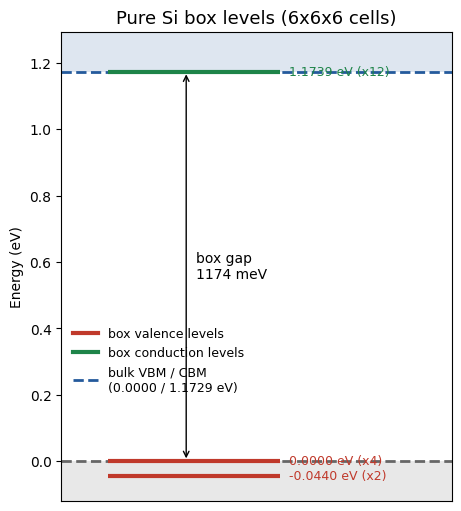

In [1]:
"""Energy levels of the pure-Si box (output of silicon_pure_box.py)."""
import numpy as np
import matplotlib.pyplot as plt

NPZ = 'results/si_box.npz'     # file written by silicon_pure_box.py
KEY = 'folded'                 # 'folded' or 'sparse' (both solvers give the same levels)
TOL = 1e-5                     # eV; levels closer than this are drawn as one (degenerate)
WIN = 0.12                     # eV; window shown below the box VBM / above the box CBM

d = np.load(NPZ)
ev, ec = d[f'{KEY}_valence_eV'], d[f'{KEY}_conduction_eV']
vbm_box, cbm_box = float(d['Ev_box_eV']), float(d['Ec_box_eV'])
vbm_bulk, cbm_bulk = float(d['vbm_bulk_eV']), float(d['cbm_bulk_eV'])

def group(energy):
    """Group degenerate levels -> list of [energy, multiplicity]."""
    out = []
    for e in np.sort(energy):
        if out and abs(e - out[-1][0]) < TOL:
            out[-1][1] += 1
        else:
            out.append([e, 1])
    return out

lo, hi = vbm_box - WIN, cbm_box + WIN
vlev = [l for l in group(ev) if l[0] >= lo]
clev = [l for l in group(ec) if l[0] <= hi]

fig, ax = plt.subplots(figsize=(4.5, 5), layout='constrained')
ax.axhspan(hi + 1, cbm_bulk, color='#245a9c', alpha=0.15, lw=0)     # bulk conduction band
ax.axhline(cbm_bulk, color='#245a9c', lw=2, ls='--')
ax.axhspan(lo - 1, vbm_bulk, color='0.7', alpha=0.3, lw=0)          # bulk valence band
ax.axhline(vbm_bulk, color='0.4', lw=2, ls='--')

for levels, col in ((vlev, '#c0392b'), (clev, '#1e8449')):
    for e, n in levels:
        ax.hlines(e, 0.15, 0.7, color=col, lw=3, zorder=3)
        ax.text(0.73, e, f'{e:.4f} eV (x{n})', va='center', fontsize=9, color=col)

ax.annotate('', (0.4, vbm_box), (0.4, cbm_box), arrowprops=dict(arrowstyle='<->', lw=1))
ax.text(0.43, 0.5 * (vbm_box + cbm_box), f'box gap\n{1000*(cbm_box - vbm_box):.0f} meV',
        va='center', fontsize=10)

ax.set(xlim=(0, 1.25), ylim=(lo, hi), xticks=[], ylabel='Energy (eV)')
ax.set_title(f'Pure Si box levels ({"x".join(map(str, d["ncells"]))} cells)', fontsize=13)
ax.legend(handles=[plt.Line2D([], [], color='#c0392b', lw=3, label='box valence levels'),
                   plt.Line2D([], [], color='#1e8449', lw=3, label='box conduction levels'),
                   plt.Line2D([], [], color='#245a9c', lw=2, ls='--', label=f'bulk VBM / CBM\n({vbm_bulk:.4f} / {cbm_bulk:.4f} eV)')],
          loc='center left', fontsize=9, frameon=False, bbox_to_anchor=(0.0, 0.3))
plt.show()


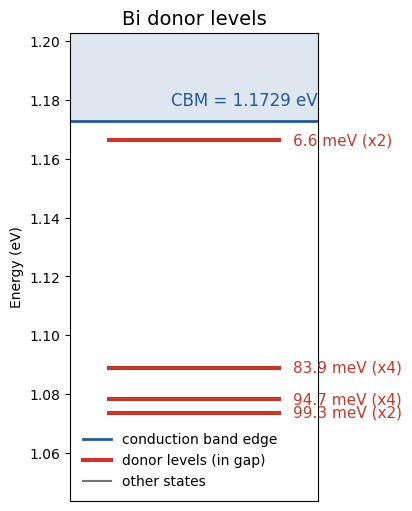

In [5]:
"""Energy levels of the Bi-donor calculation (output of silicon_bi_donor.py)."""
import numpy as np
import matplotlib.pyplot as plt

NPZ = 'results/bi_donor.npz'   # file written by silicon_bi_donor.py
TOL = 1e-5                     # eV; levels closer than this are drawn as one (degenerate)

d = np.load(NPZ)
energy, cbm, vbm = d['energy_eV'], float(d['cbm_eV']), float(d['vbm_eV'])
donor = (energy > vbm) & (energy < cbm)          # levels inside the bulk gap, below the CBM

# group degenerate levels: (energy, multiplicity, is_donor)
levels = []
for e, is_d in zip(energy, donor):
    if levels and abs(e - levels[-1][0]) < TOL:
        levels[-1][1] += 1
    else:
        levels.append([e, 1, is_d])

fig, ax = plt.subplots(figsize=(4, 5), layout='constrained')
lo = min(energy.min(), cbm) - 0.03
hi = max(energy.max(), cbm) + 0.03
ax.axhspan(cbm, hi + 1, color='#245a9c', alpha=0.15, lw=0)       # conduction band
ax.axhline(cbm, color='#245a9c', lw=2)
ax.text(1.0, cbm + 0.004, f'CBM = {cbm:.4f} eV', ha='right', va='bottom',
        color='#245a9c', fontsize=12)
if vbm > lo:
    ax.axhspan(lo - 1, vbm, color='0.7', alpha=0.3, lw=0)       # valence band
    ax.axhline(vbm, color='0.4', lw=2)

for e, n, is_d in levels:
    ax.hlines(e, 0.15, 0.85, color='#c0392b' if is_d else '0.45',
              lw=3 if is_d else 1.5, zorder=3)
    if is_d:
        ax.text(0.9, e, f'{1000*(cbm-e):.1f} meV' + (f' (x{n})' if n > 1 else ''),
                va='center', fontsize=11, color='#c0392b')

ax.set(xlim=(0, 1.0), ylim=(lo, hi), xticks=[], ylabel='Energy (eV)')
ax.set_title('Bi donor levels', fontsize=14)
ax.legend(handles=[plt.Line2D([], [], color='#245a9c', lw=2, label='conduction band edge'),
                   plt.Line2D([], [], color='#c0392b', lw=3, label='donor levels (in gap)'),
                   plt.Line2D([], [], color='0.45', lw=1.5, label='other states')],
          loc='lower left', fontsize=10, frameon=False)
plt.show()
